# Dice Throne: hero vs hero shaping
Load, dedupe, and reshape games into hero-vs-hero results. No modelling yet.

In [15]:
import json
from pathlib import Path

import pandas as pd

DATA_FILE = Path('dt-data-for-log-reg.txt')
MIN_GAMES = 5  # threshold for a hero pair to count as 'enough' data

## 1. Import
The file holds two JSON arrays back to back, so decode them one at a time.

In [16]:
text = DATA_FILE.read_text(encoding='utf-8')
decoder = json.JSONDecoder()
arrays, pos = [], 0
while True:
    while pos < len(text) and text[pos].isspace():
        pos += 1
    if pos >= len(text):
        break
    arr, pos = decoder.raw_decode(text, pos)
    arrays.append(arr)

print('records per array:', [len(a) for a in arrays])
raw = pd.DataFrame([r for a in arrays for r in a])
print('total raw records:', len(raw))
raw.head(3)

records per array: [19, 14]
total raw records: 33


,ts,app,gsi1sk,user,pk,game,gsi1pk,sk
0,2026-09-25T16:14:31.965Z,tca-dice-throne-26s,2026-09-25T16:14:31.965Z,Joshua105@yahoo.com,joshua105@yahoo.com,"{'start': '2026-09-25T16:14:28.723Z', 'winner'...",tca-dice-throne-26s,tca-dice-throne-26s#2026-09-25T16:14:31.965Z
1,2026-09-25T16:14:44.167Z,tca-dice-throne-26s,2026-09-25T16:14:44.167Z,Joshua105@yahoo.com,joshua105@yahoo.com,"{'start': '2026-09-25T16:14:42.179Z', 'end': '...",tca-dice-throne-26s,tca-dice-throne-26s#2026-09-25T16:14:44.167Z
2,2026-09-25T16:59:29.228Z,tca-dice-throne-26s,2026-09-25T16:59:29.228Z,Joshua105@yahoo.com,joshua105@yahoo.com,"{'end': '2026-09-25T16:59:29.228Z', 'players':...",tca-dice-throne-26s,tca-dice-throne-26s#2026-09-25T16:59:29.228Z


## 2. Dedupe
A game is identified by start + end (not user, since games were copied between users).

In [17]:
raw['game_start'] = raw['game'].map(lambda g: g.get('start'))
raw['game_end'] = raw['game'].map(lambda g: g.get('end'))
key = ['game_start', 'game_end']  # games were copied between users, so user is not part of the key
print('duplicate records:', raw.duplicated(key).sum())
# do any duplicates disagree on content?
raw['game_json'] = raw['game'].map(lambda g: json.dumps(g, sort_keys=True))
print('keys with conflicting game content:', (raw.groupby(key)['game_json'].nunique() > 1).sum())
dedup = raw.drop_duplicates(key).reset_index(drop=True)
print('after dedupe:', len(dedup))
raw.groupby(key)['user'].nunique().value_counts().rename('games by number of users holding them')

duplicate records: 13
keys with conflicting game content: 0
after dedupe: 20


user
2    13
1     7
Name: games by number of users holding them, dtype: int64

## 3. Flatten to one row per game

In [18]:
rows, problems = [], []
for _, r in dedup.iterrows():
    g = r['game']
    players = g.get('players', [])
    winner = g.get('winner')
    if len(players) != 2:
        problems.append((r['game_start'], 'players != 2'))
        continue
    if not winner:
        problems.append((r['game_start'], 'no winner'))
        continue
    names = [p['name'] for p in players]
    if winner not in names:
        problems.append((r['game_start'], 'winner not a player'))
        continue
    p1, p2 = players
    rows.append({'user': r['user'], 'start': g['start'], 'end': g.get('end'),
                 'p1_name': p1['name'], 'p1_hero': p1.get('hero'),
                 'p2_name': p2['name'], 'p2_hero': p2.get('hero'),
                 'winner_name': winner})
games = pd.DataFrame(rows)
games['winner_hero'] = games.apply(lambda x: x.p1_hero if x.winner_name == x.p1_name else x.p2_hero, axis=1)
print('usable games:', len(games), '| dropped:', pd.Series([p[1] for p in problems]).value_counts().to_dict())
print('missing hero:', games[['p1_hero', 'p2_hero']].isna().sum().to_dict())
games.head()

usable games: 20 | dropped: {}
missing hero: {'p1_hero': 0, 'p2_hero': 0}


,user,start,end,p1_name,p1_hero,p2_name,p2_hero,winner_name,winner_hero
0,Joshua105@yahoo.com,2026-09-25T16:14:28.723Z,2026-09-25T16:14:31.965Z,Josh,Headless Horseman,Tom,Pale Lady,Tom,Pale Lady
1,Joshua105@yahoo.com,2026-09-25T16:14:42.179Z,2026-09-25T16:14:44.167Z,Josh,Headless Horseman,Tom,Pale Lady,Josh,Headless Horseman
2,Joshua105@yahoo.com,2026-09-25T16:59:27.516Z,2026-09-25T16:59:29.228Z,Josh,Scarlet Witch,Tom,Spiderman,Tom,Spiderman
3,Joshua105@yahoo.com,2026-09-25T16:59:44.150Z,2026-09-25T16:59:45.714Z,Josh,Loki,Tom,Spiderman,Tom,Spiderman
4,Joshua105@yahoo.com,2026-09-25T16:59:53.445Z,2026-09-25T16:59:55.069Z,Josh,Loki,Tom,Spiderman,Tom,Spiderman


In [19]:
# which hero does each player use?
pl = pd.concat([games[['p1_name', 'p1_hero']].set_axis(['name', 'hero'], axis=1),
                games[['p2_name', 'p2_hero']].set_axis(['name', 'hero'], axis=1)])
pl.groupby(['name', 'hero']).size().unstack(fill_value=0)

hero,Gunslinger,Headless Horseman,Loki,Moon Elf,Ninja,Pale Lady,Samurai,Scarlet Witch,Spiderman,Sun Elf,Thor,Treant
name,,,,,,,,,,,,
Anna,0,1,1,1,0,2,0,0,0,1,0,0
Josh,1,4,5,2,0,0,2,2,1,0,1,1
Taylor,0,0,0,0,1,0,0,0,0,0,0,0
Tom,0,0,0,0,1,4,2,0,5,1,1,0


## 4. Hero vs hero rows
One row per game per orientation (hero_a perspective), so each game appears twice with `a_won` flipped.

In [20]:
a = pd.DataFrame({'start': games.start, 'hero_a': games.p1_hero, 'hero_b': games.p2_hero, 'a_won': (games.winner_name == games.p1_name).astype(int)})
b = pd.DataFrame({'start': games.start, 'hero_a': games.p2_hero, 'hero_b': games.p1_hero, 'a_won': (games.winner_name == games.p2_name).astype(int)})
h2h = pd.concat([a, b], ignore_index=True)
print(len(h2h), 'rows')
h2h.head()

40 rows


,start,hero_a,hero_b,a_won
0,2026-09-25T16:14:28.723Z,Headless Horseman,Pale Lady,0
1,2026-09-25T16:14:42.179Z,Headless Horseman,Pale Lady,1
2,2026-09-25T16:59:27.516Z,Scarlet Witch,Spiderman,0
3,2026-09-25T16:59:44.150Z,Loki,Spiderman,0
4,2026-09-25T16:59:53.445Z,Loki,Spiderman,0


## 5. Which matchups have enough data?

In [21]:
hero_totals = h2h.groupby('hero_a').agg(games=('a_won', 'size'), wins=('a_won', 'sum'))
hero_totals['win_rate'] = (hero_totals.wins / hero_totals.games).round(2)
hero_totals.sort_values('games', ascending=False)

,games,wins,win_rate
hero_a,,,
Loki,6,2,0.33
Pale Lady,6,2,0.33
Spiderman,6,3,0.50
Headless Horseman,5,3,0.60
Samurai,4,2,0.50
Moon Elf,3,3,1.00
Scarlet Witch,2,1,0.50
Ninja,2,0,0.00
Thor,2,2,1.00


In [22]:
pairs = h2h.groupby(['hero_a', 'hero_b']).agg(games=('a_won', 'size'), a_wins=('a_won', 'sum')).reset_index()
pairs['a_win_rate'] = (pairs.a_wins / pairs.games).round(2)
# unordered view: each pair once
unordered = pairs[pairs.hero_a < pairs.hero_b].sort_values('games', ascending=False)
unordered[unordered.games >= MIN_GAMES] if (unordered.games >= MIN_GAMES).any() else unordered.head(15)

,hero_a,hero_b,games,a_wins,a_win_rate
8,Loki,Spiderman,3,1,0.33
2,Headless Horseman,Pale Lady,2,1,0.50
10,Moon Elf,Sun Elf,2,2,1.00
3,Headless Horseman,Samurai,1,1,1.00
4,Headless Horseman,Spiderman,1,1,1.00
5,Loki,Pale Lady,1,1,1.00
6,Loki,Samurai,1,0,0.00
0,Gunslinger,Headless Horseman,1,1,1.00
7,Loki,Scarlet Witch,1,0,0.00
9,Moon Elf,Samurai,1,1,1.00


In [23]:
# games-per-matchup matrix (symmetric)
counts = pairs.pivot(index='hero_a', columns='hero_b', values='games').fillna(0).astype(int)
counts.style.background_gradient(cmap='Blues')

hero_b,Gunslinger,Headless Horseman,Loki,Moon Elf,Ninja,Pale Lady,Samurai,Scarlet Witch,Spiderman,Sun Elf,Thor,Treant
hero_a,,,,,,,,,,,,
Gunslinger,0,1,0,0,0,0,0,0,0,0,0,0
Headless Horseman,1,0,0,0,0,2,1,0,1,0,0,0
Loki,0,0,0,0,0,1,1,1,3,0,0,0
Moon Elf,0,0,0,0,0,0,1,0,0,2,0,0
Ninja,0,0,0,0,0,1,0,0,0,0,1,0
Pale Lady,0,2,1,0,1,0,1,0,0,0,0,1
Samurai,0,1,1,1,0,1,0,0,0,0,0,0
Scarlet Witch,0,0,1,0,0,0,0,0,1,0,0,0
Spiderman,0,1,3,0,0,0,0,1,0,0,1,0


In [24]:
# win rate of row hero vs column hero
rates = pairs.pivot(index='hero_a', columns='hero_b', values='a_win_rate')
rates.style.background_gradient(cmap='RdYlGn', vmin=0, vmax=1).format('{:.2f}', na_rep='')

hero_b,Gunslinger,Headless Horseman,Loki,Moon Elf,Ninja,Pale Lady,Samurai,Scarlet Witch,Spiderman,Sun Elf,Thor,Treant
hero_a,,,,,,,,,,,,
Gunslinger,,1.00,,,,,,,,,,
Headless Horseman,0.00,,,,,0.50,1.00,,1.00,,,
Loki,,,,,,1.00,0.00,0.00,0.33,,,
Moon Elf,,,,,,,1.00,,,1.00,,
Ninja,,,,,,0.00,,,,,0.00,
Pale Lady,,0.50,0.00,,1.00,,0.00,,,,,0.00
Samurai,,0.00,1.00,0.00,,1.00,,,,,,
Scarlet Witch,,,1.00,,,,,,0.00,,,
Spiderman,,0.00,0.67,,,,,1.00,,,0.00,


## 6. What-if: synthetic data, opponent hero vs Spiderman
Real data is too thin for a fit, so this section **synthesizes** games to visualize what logistic regression could look like with more data.

- y = 1 if the opponent hero beats Spiderman, 0 if it loses
- x = opponent hero, one-hot encoded
- Synthetic labels are drawn from the real (smoothed, jittered) win rates, so the fit shows the *shape* of the result, not new evidence.

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

TARGET = 'Spiderman'
N_SYNTH = 500
PRIOR = 1.0  # Beta smoothing pseudo-games per outcome
JITTER = 10.0  # Beta concentration; lower = more jitter
FREQ_FLOOR = 1  # pseudo-games so rare opponents still appear
rng = np.random.default_rng(42)

real = h2h[(h2h.hero_b == TARGET) & (h2h.hero_a != TARGET)]
real_stats = real.groupby('hero_a').agg(games=('a_won', 'size'), wins=('a_won', 'sum'))
real_stats['raw_rate'] = (real_stats.wins / real_stats.games).round(2)
print(f'real games vs {TARGET}:', len(real))
real_stats.sort_values('games', ascending=False)

real games vs Spiderman: 6


,games,wins,raw_rate
hero_a,,,
Loki,3,1,0.33
Headless Horseman,1,1,1.00
Scarlet Witch,1,0,0.00
Thor,1,1,1.00


In [26]:
# smoothed per-hero rate, then jitter it with a Beta draw around that rate
smooth = (real_stats.wins + PRIOR) / (real_stats.games + 2 * PRIOR)
jittered = pd.Series(rng.beta(smooth * JITTER, (1 - smooth) * JITTER), index=smooth.index)

freq = real_stats.games + FREQ_FLOOR
heroes = rng.choice(freq.index, size=N_SYNTH, p=freq / freq.sum())
won = rng.binomial(1, jittered.loc[heroes].to_numpy())
synth = pd.DataFrame({'opponent': heroes, 'won': won})

compare = pd.DataFrame({'real_rate': real_stats.raw_rate, 'smoothed': smooth.round(2),
                        'jittered_true': jittered.round(2),
                        'synth_rate': synth.groupby('opponent').won.mean().round(2),
                        'synth_games': synth.opponent.value_counts()})
compare.sort_values('synth_games', ascending=False)

,real_rate,smoothed,jittered_true,synth_rate,synth_games
Loki,0.33,0.40,0.41,0.40,189
Headless Horseman,1.00,0.67,0.61,0.58,113
Scarlet Witch,0.00,0.33,0.42,0.43,105
Thor,1.00,0.67,0.67,0.70,93


### One-hot encode and fit

In [27]:
X = pd.get_dummies(synth.opponent).astype(int)
y = synth.won
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

model = LogisticRegression(max_iter=1000)  # L2 regularized, so all hero columns are identifiable
model.fit(X_tr, y_tr)
print('held-out accuracy:', round(model.score(X_te, y_te), 3), '| baseline (majority):', round(max(y_te.mean(), 1 - y_te.mean()), 3))

b0 = model.intercept_[0]
coefs = pd.DataFrame({'b': model.coef_[0]}, index=X.columns)
coefs['odds_ratio'] = np.exp(coefs.b)
coefs['z = b0 + b'] = b0 + coefs.b
coefs['p(win)'] = 1 / (1 + np.exp(-coefs['z = b0 + b']))
print(f'b0 (intercept) = {b0:.3f}')
coefs.round(3).sort_values('b', ascending=False)

held-out accuracy: 0.616 | baseline (majority): 0.504
b0 (intercept) = 0.085


,b,odds_ratio,z = b0 + b,p(win)
Thor,0.653,1.921,0.738,0.677
Headless Horseman,0.228,1.256,0.313,0.578
Scarlet Witch,-0.375,0.687,-0.290,0.428
Loki,-0.432,0.649,-0.347,0.414


### The S-curve
Each opponent hero has one score z = b0 + b_hero. The curve is p = 1 / (1 + e^-z); every hero sits at one point on it (point size = synthetic games).

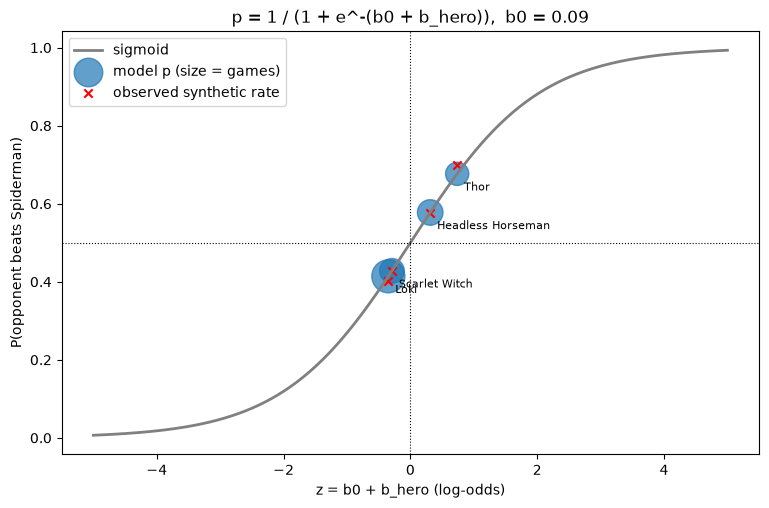

In [28]:
z = np.linspace(-5, 5, 300)
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(z, 1 / (1 + np.exp(-z)), color='gray', lw=2, label='sigmoid')

obs = synth.groupby('opponent').won.agg(['mean', 'size'])
ax.scatter(coefs['z = b0 + b'], coefs['p(win)'], s=obs['size'].loc[coefs.index] * 3, alpha=0.7, label='model p (size = games)')
ax.scatter(coefs['z = b0 + b'], obs['mean'].loc[coefs.index], marker='x', color='red', label='observed synthetic rate')
for hero, row in coefs.iterrows():
    ax.annotate(hero, (row['z = b0 + b'], row['p(win)']), textcoords='offset points', xytext=(5, -12), fontsize=8)
ax.axhline(0.5, ls=':', color='k', lw=0.8)
ax.axvline(0, ls=':', color='k', lw=0.8)
ax.set_xlabel('z = b0 + b_hero (log-odds)')
ax.set_ylabel(f'P(opponent beats {TARGET})')
ax.set_title(f'p = 1 / (1 + e^-(b0 + b_hero)),  b0 = {b0:.2f}')
ax.legend(loc='upper left')
plt.show()

## 7. Hero strength model (Bradley-Terry) for matchups never seen
Section 6 was a lookup: each hero's b is just its record vs Spiderman, so it says nothing about heroes who never faced him.

Instead, encode each game as **+1 for hero A, -1 for hero B** (no intercept) and fit logistic regression. Each hero gets one strength `s`, and `P(A beats B) = sigmoid(s_A - s_B)`. Heroes can now be compared through **common opponents**, as long as the matchup graph is connected.

In [29]:
all_heroes = sorted(set(games.p1_hero) | set(games.p2_hero))
idx = {h: i for i, h in enumerate(all_heroes)}

def signed_matrix(a_heroes, b_heroes):
    M = np.zeros((len(a_heroes), len(all_heroes)))
    for r, (a, b) in enumerate(zip(a_heroes, b_heroes)):
        M[r, idx[a]] += 1
        M[r, idx[b]] -= 1
    return M

# connected components of the matchup graph (union-find)
parent = {h: h for h in all_heroes}
def find(h):
    while parent[h] != h:
        parent[h] = parent[parent[h]]
        h = parent[h]
    return h
for a, b in zip(games.p1_hero, games.p2_hero):
    parent[find(a)] = find(b)
comp = {}
for h in all_heroes:
    comp.setdefault(find(h), []).append(h)
components = list(comp.values())
print('connected groups of heroes:', len(components))
for c in components:
    print(' ', len(c), 'heroes:', c)

connected groups of heroes: 1
  12 heroes: ['Gunslinger', 'Headless Horseman', 'Loki', 'Moon Elf', 'Ninja', 'Pale Lady', 'Samurai', 'Scarlet Witch', 'Spiderman', 'Sun Elf', 'Thor', 'Treant']


In [30]:
# real data: use h2h rows (both orientations) so the classes are balanced
X_bt = signed_matrix(h2h.hero_a, h2h.hero_b)
bt = LogisticRegression(fit_intercept=False, C=1.0, max_iter=1000).fit(X_bt, h2h.a_won)
strength = pd.Series(bt.coef_[0], index=all_heroes).sort_values(ascending=False)

seen = set(real.hero_a)
pred = pd.DataFrame({'strength': strength.round(2)})
pred[f'P(beats {TARGET})'] = (1 / (1 + np.exp(-(strength - strength[TARGET])))).round(2)
pred['faced Spiderman?'] = ['yes' if h in seen else ('-' if h == TARGET else 'no (inferred)') for h in pred.index]
pred

,strength,P(beats Spiderman),faced Spiderman?
Moon Elf,1.10,0.78,no (inferred)
Thor,0.82,0.73,yes
Gunslinger,0.74,0.71,no (inferred)
Treant,0.49,0.66,no (inferred)
Headless Horseman,0.20,0.59,yes
Samurai,-0.01,0.54,no (inferred)
Spiderman,-0.16,0.50,-
Scarlet Witch,-0.21,0.49,yes
Sun Elf,-0.61,0.39,no (inferred)
Pale Lady,-0.63,0.38,no (inferred)


Strengths are shrunk by regularization because real data is thin. Heroes marked *inferred* get a prediction only through common opponents.

### Synthetic what-if: can it predict pairs it never saw?
Invent true strengths for every hero, simulate games between random pairs, **withhold every game involving Spiderman vs a few chosen heroes**, fit, and compare.

In [31]:
rng2 = np.random.default_rng(7)
N_BT = 1500
true_s = pd.Series(rng2.normal(0, 1, len(all_heroes)), index=all_heroes)

held_out_heroes = [h for h in all_heroes if h != TARGET][:3]  # never allowed to face TARGET
banned = {frozenset((TARGET, h)) for h in held_out_heroes}

pairs_sim = []
while len(pairs_sim) < N_BT:
    a, b = rng2.choice(all_heroes, 2, replace=False)
    if frozenset((a, b)) not in banned:
        pairs_sim.append((a, b))
sim = pd.DataFrame(pairs_sim, columns=['hero_a', 'hero_b'])
p_true = 1 / (1 + np.exp(-(true_s[sim.hero_a].to_numpy() - true_s[sim.hero_b].to_numpy())))
sim['a_won'] = rng2.binomial(1, p_true)

bt_sim = LogisticRegression(fit_intercept=False, C=10.0, max_iter=1000).fit(signed_matrix(sim.hero_a, sim.hero_b), sim.a_won)
est_s = pd.Series(bt_sim.coef_[0], index=all_heroes)

rows = []
for h in held_out_heroes:
    rows.append({'matchup': f'{h} vs {TARGET}', 'games_seen': 0,
                 'true_P': 1 / (1 + np.exp(-(true_s[h] - true_s[TARGET]))),
                 'predicted_P': 1 / (1 + np.exp(-(est_s[h] - est_s[TARGET])))})
withheld = pd.DataFrame(rows).round(3)
print('correlation true vs estimated strengths:', round(np.corrcoef(true_s, est_s)[0, 1], 3))
withheld

correlation true vs estimated strengths: 0.989


,matchup,games_seen,true_P,predicted_P
0,Gunslinger vs Spiderman,0,0.621,0.623
1,Headless Horseman vs Spiderman,0,0.688,0.683
2,Loki vs Spiderman,0,0.554,0.560


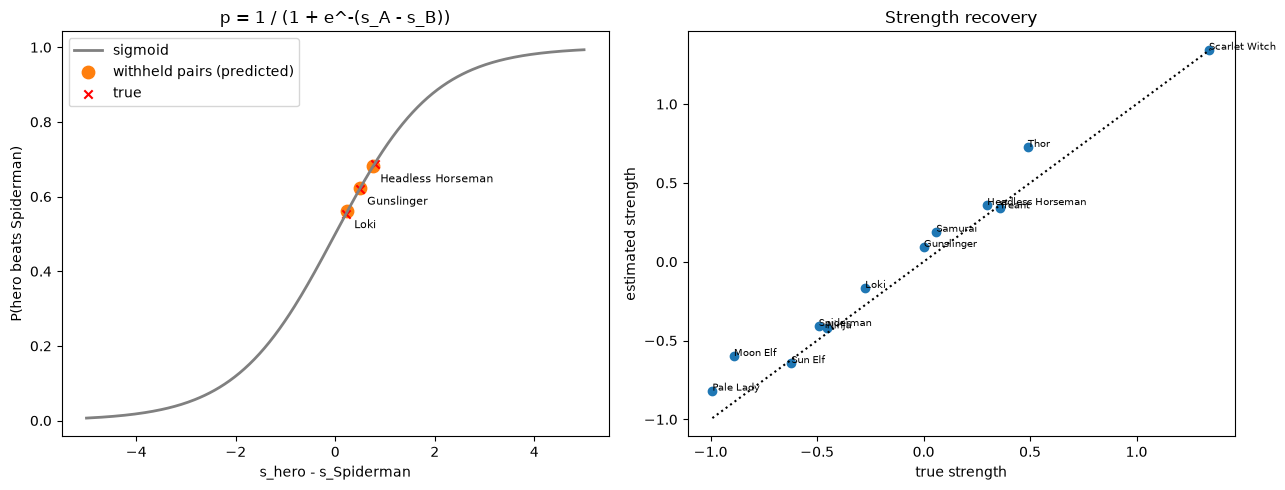

In [32]:
d = np.linspace(-5, 5, 300)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(d, 1 / (1 + np.exp(-d)), color='gray', lw=2, label='sigmoid')
diffs = np.array([est_s[h] - est_s[TARGET] for h in held_out_heroes])
axes[0].scatter(diffs, 1 / (1 + np.exp(-diffs)), color='C1', s=80, label='withheld pairs (predicted)')
axes[0].scatter([true_s[h] - true_s[TARGET] for h in held_out_heroes], withheld.true_P, marker='x', color='red', label='true')
for h, x in zip(held_out_heroes, diffs):
    axes[0].annotate(h, (x, 1 / (1 + np.exp(-x))), textcoords='offset points', xytext=(5, -12), fontsize=8)
axes[0].set_xlabel('s_hero - s_Spiderman'); axes[0].set_ylabel('P(hero beats Spiderman)')
axes[0].set_title('p = 1 / (1 + e^-(s_A - s_B))'); axes[0].legend()

axes[1].scatter(true_s, est_s)
lim = [min(true_s.min(), est_s.min()), max(true_s.max(), est_s.max())]
axes[1].plot(lim, lim, ls=':', color='k')
for h in all_heroes:
    axes[1].annotate(h, (true_s[h], est_s[h]), fontsize=7)
axes[1].set_xlabel('true strength'); axes[1].set_ylabel('estimated strength'); axes[1].set_title('Strength recovery')
plt.tight_layout(); plt.show()